# Filtered back projection (CT): windows and memory

Filtered back projection (FBP) is how CT scanners have reconstructed their images for decades: each projection is filtered with a ramp times a window, then back projected. In PyTomography it is one algorithm, `FilteredBackProjection`, which takes the projections and a system matrix; the system matrix does the work in its own geometry. This tutorial uses it on a helical chest CT from a GE scanner and looks at the two choices it leaves to the user: the window, which trades resolution against noise, and the memory it may use, which `estimate_memory` predicts and `plan_memory` fits to the memory there is. The [DICOM-CT-PD tutorial](t_CT_GEN3.ipynb) reconstructs the same scan as a clinical workflow, up to reproducing the scanner's own images, and the [SPECT version](t_fbp_spect.ipynb) uses the same class on a SPECT scan.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("CT/ldct-c145")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("CT/ldct-c145")

CT/ldct-c145: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import ndimage
import pytomography
from pytomography import io
from pytomography.metadata import ObjectMeta
from pytomography.projectors.CT import CTGen3SystemMatrix
from pytomography.algorithms import FilteredBackProjection
from pytomography.utils import get_fbp_filter, HannFilter, PeakMemory

In [3]:
# Memory: this tutorial needs about 13 GB of RAM: 2 GB of projections, the images it keeps, the reconstruction's
# chunks of views and the GPU libraries. RAM_GB caps what the reconstruction uses for its own work: with less, it
# rebins and filters fewer views at a time, which is a little slower and gives the same image. Section 3 prints the
# estimate before anything runs (estimate_memory) and the settings that fit less memory (plan_memory); section 4
# reconstructs with them. Most of the 13 GB is not the reconstruction's own, so a lower RAM_GB saves a few GB at most.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The projections

The scan is the full-dose chest CT of case C145 in The Cancer Imaging Archive's LDCT-and-Projection-data collection, from a GE Discovery CT750 HD: 9,014 views of a helical scan, each 888 detector columns by 64 rows, in DICOM-CT-PD format. `io.CT.read_dicom_ct_pd` puts the views in order, takes the whole geometry from the files, filters rays that received too few photons, and gives the attenuation of water, which converts the image to Hounsfield units; the [DICOM-CT-PD tutorial](t_CT_GEN3.ipynb) explains each step. The image grid is the scanner's own: 512 × 512 pixels of 0.662 mm, in 316 slices 1 mm apart, which the reader places in the patient (`object_meta`), with the slices running from the feet to the head.

In [4]:
folder = DATA / 'CT' / 'ldct-c145'
t0 = time.time()
proj, object_meta, proj_meta = io.CT.read_dicom_ct_pd(
    folder / 'full_dose_projections',
    object_meta=ObjectMeta(dr=(0.662109, 0.662109, 1.0), shape=(512, 512, 316)))  # mm, voxels: the scanner's grid
print(f"{proj.shape[0]} views of {proj.shape[1]} x {proj.shape[2]} detector elements, read in {time.time() - t0:.0f} s")
behind = proj_meta.photon_counts[::100, :, None] * torch.exp(-proj[::100])  # every 100th view
print(f"photons reaching a detector element, median over the rays through the patient: {behind[proj[::100] > 1].median():.0f}")
system_matrix = CTGen3SystemMatrix(object_meta, proj_meta)
to_hu = lambda image: io.CT.to_hu(image, proj_meta).cpu().numpy()

9014 views of 888 x 64 detector elements, read in 25 s
photons reaching a detector element, median over the rays through the patient: 779


## 2. Ramp and window

Each projection holds the line integrals of attenuation along its rays. Back projection spreads each one back along its rays and adds up the views; on its own it gives a blurred image, every point smeared out as $1/r$. Multiplying the spectrum of each projection by the ramp $|f|$ before back projecting removes that blur exactly, but it also amplifies noise, which is strongest at high spatial frequencies. The window $W(f)$ multiplies the ramp to tame it, and it is the main choice FBP leaves to the user: `filter` takes a name (`'ram-lak'`, no window; `'shepp-logan'`, `'cosine'`, `'hamming'`, `'hann'`), a window with a cut-off such as `HannFilter(cutoff=0.5)`, or any function of the spatial frequency in cycles per mm.

CT projections are made of many photons: even through the patient, the median ray brings several hundred to its detector element, and there are 9,014 views. The noise is low enough for windows that keep frequencies up to the Nyquist frequency of the rays, set by their spacing after the fans are rebinned to parallel rays. The windows this tutorial compares:

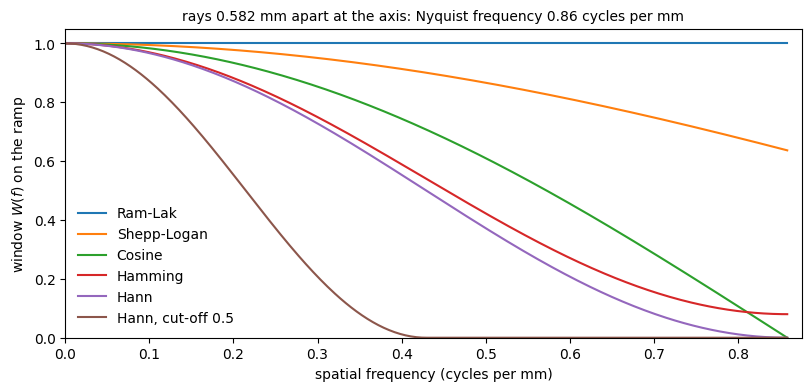

In [5]:
dt = float(proj_meta.source_rhos.double().mean()) * abs(float(proj_meta.col_angle_spacing))  # mm between parallel rays at the axis
f_nyquist = 1 / (2 * dt)
windows = {'Ram-Lak': 'ram-lak', 'Shepp-Logan': 'shepp-logan', 'Cosine': 'cosine', 'Hamming': 'hamming', 'Hann': 'hann',
           'Hann, cut-off 0.5': HannFilter(cutoff=0.5)}
f = torch.linspace(0, f_nyquist, 400)
bandwidth = {}  # the frequency up to which a sharp cut-off would pass as much as the window
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
for name, window in windows.items():
    W = get_fbp_filter(window)(f, f_nyquist)
    bandwidth[name] = float(torch.trapezoid(W, f))
    ax.plot(f, W, label=name)
ax.set(xlabel='spatial frequency (cycles per mm)', ylabel='window $W(f)$ on the ramp', xlim=(0, f_nyquist * 1.02), ylim=(0, 1.05))
ax.set_title(f'rays {dt:.3f} mm apart at the axis: Nyquist frequency {f_nyquist:.2f} cycles per mm', fontsize=10)
ax.legend(frameon=False, loc='lower left')
plt.show()

## 3. Memory, before reconstructing

The helical geometry is what makes CT's FBP different. The source travels on a helix and each view is a fan of rays, so the reconstruction first rebins the fans into sets of parallel rays, filters those, and back projects them with weights that combine the overlapping turns of the helix (weighted FBP, WFBP). Two options belong to it:

- `slice_thickness`: the projections sample the table position continuously, so each slice can be the average over any length of table; `1.25` gives slices 1.25 mm thick like the scanner's, while the grid places them 1 mm apart. Thicker slices are less noisy (section 5). In SPECT and in cone-beam CT the slices are simply the voxels of the grid.
- `gpu_budget`: the GPU memory the rebinning, filtering and back projection may hold at once (1.5 GB by default). The host memory they hold follows `pytomography.set_memory_budget`. Less of either means fewer views at a time: slower, the same image.

`estimate_memory` gives the peak RAM and GPU memory before anything runs, with what they are made of. For comparison, an iterative reconstruction of the same scan, OS-SART with 40 subsets, keeps an image per subset:

In [6]:
fbp = FilteredBackProjection(proj, system_matrix, filter='hann', slice_thickness=1.25)
print(fbp.estimate_memory())
print()
print(system_matrix.estimate_memory(n_subsets=40, held={'projections': proj}))

Filtered back projection (CTGen3SystemMatrix)
Peak ~ 13.3 GB RAM, 3.7 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 2.0 GB RAM, 0.3 GB GPU (projections 2.0 RAM, image 0.3 GPU)
  projector chunks: 2.2 GB RAM, 1.9 GB GPU (rebinned views of one chunk 1.9 RAM, views being rebinned or filtered 0.2 RAM, rebinning, filtering and back projection buffers 1.9 GPU)
  Python, CUDA, allocator: 5.3 GB RAM, 1.5 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.8 GPU, memory the allocators keep (Windows) 2.3 RAM)
To use less: set_memory_budget(8) ~ 12.0 GB RAM, 3.7 GB GPU, gpu_budget=0.75e9 ~ 12.0 GB RAM, 2.7 GB GPU
(plus whatever else your script keeps)

CTGen3SystemMatrix: 40 subsets, memory budget 25 GB
Peak ~ 29.7 GB RAM, 4.9 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 15.3 GB RAM, 0.3 GB GPU (image 0.3 GPU, H_m^T 1 of 40 subsets 13.

`plan_memory` answers the opposite question: the fastest settings that fit given amounts of RAM and GPU memory, here 10 GB of RAM and 2 GB of GPU memory.

In [7]:
plan = fbp.plan_memory(ram_gb=10, gpu_gb=2)
print(plan)

Memory plan for Filtered back projection (CTGen3SystemMatrix), in 10.0 GB RAM and 2.0 GB GPU (on Windows, GPU memory counts as RAM too)
Fits: gpu_budget=1.5e+09, memory_budget_gb=0.12 ~ 8.0 GB RAM, 1.8 GB GPU
Tried (8):
  gpu_budget  memory_budget_gb  RAM GB  GPU GB  fits
     1.5e+09                25    13.3     3.7  no
     1.5e+09               7.7    12.0     3.7  no
     1.5e+09               3.9    11.3     3.7  no
     1.5e+09               1.9    11.0     3.7  no
     1.5e+09              0.97    10.8     3.7  no
     1.5e+09              0.48     9.8     3.1  no
     1.5e+09              0.24     8.5     2.1  no
     1.5e+09              0.12     8.0     1.8  yes  <- chosen


## 4. Reconstruct, with the default settings and with the plan's

`PeakMemory` measures the GPU memory a step takes, to set beside the estimates.

In [8]:
t0 = time.time()
with PeakMemory() as peak:
    hu = to_hu(fbp())
print(f"default settings: {time.time() - t0:.0f} s, GPU peak {peak.peak / 1e9:.2f} GB")

pytomography.set_memory_budget(plan.settings['memory_budget_gb'])
fbp_planned = FilteredBackProjection(proj, system_matrix, filter='hann', slice_thickness=1.25, gpu_budget=plan.settings['gpu_budget'])
print(fbp_planned.estimate_memory())
t0 = time.time()
with PeakMemory() as peak:
    hu_planned = to_hu(fbp_planned())
print(f"the plan's settings: {time.time() - t0:.0f} s, GPU peak {peak.peak / 1e9:.2f} GB; "
      f"largest difference from the default image: {np.abs(hu_planned - hu).max():.1e} HU")
pytomography.set_memory_budget(RAM_GB)
del hu_planned

default settings: 15 s, GPU peak 1.30 GB


Filtered back projection (CTGen3SystemMatrix)
Peak ~ 8.0 GB RAM, 1.8 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 2.0 GB RAM, 0.3 GB GPU (projections 2.0 RAM, image 0.3 GPU)
  projector chunks: 0.1 GB RAM, 0.5 GB GPU (rebinned views of one chunk 0.01 RAM, views being rebinned or filtered 0.1 RAM, rebinning, filtering and back projection buffers 0.5 GPU)
  Python, CUDA, allocator: 4.1 GB RAM, 1.0 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.3 GPU, memory the allocators keep (Windows) 1.0 RAM)
To use less: set_memory_budget(0.06) ~ 7.9 GB RAM, 1.7 GB GPU
(plus whatever else your script keeps)


the plan's settings: 15 s, GPU peak 0.99 GB; largest difference from the default image: 6.8e-03 HU


The plan keeps `gpu_budget` and lowers the memory budget to 0.12 GB, so each chunk of rebinned views the host holds shrinks from 1.9 GB to 0.01 GB, and with it the buffers on the GPU. Here it costs no time, lowers the measured GPU peak by about a quarter, and gives the same image to within a few thousandths of a HU, the rounding of floating point. `PeakMemory` measures what PyTorch allocated; the estimates add what its cache and the Windows allocators keep on top, so they are the safer numbers to plan with.

## 5. Windows compared

The scanner's own reconstruction of this scan comes with the data. `io.load_image` reads the scanner's images with their place in the patient, and `.on(object_meta)` resamples them onto our grid. GE's `ImagePositionPatient` marks the corner of the first pixel rather than its centre, as DICOM defines it; `load_image` knows this rule of GE's (PyTomography's vendor table), so nothing needs correcting here.

In [9]:
scanner_files = sorted((folder / 'full_dose_images').glob('*.dcm'))
scanner = io.load_image(scanner_files)  # in HU, with its place in the patient
scanner_hu = scanner.on(object_meta, fill=-3000).cpu().numpy()  # -3000: outside the scanner's images

Each window, and Hann without `slice_thickness`, reconstructs the scan once more; the noise is the standard deviation of a 26 × 26 × 16 mm block of liver, where the tissue is uniform. Each reconstruction prints its estimate first: the window changes the filter's values, not the memory.

In [10]:
liver = (slice(100, 140), slice(200, 240), slice(20, 36))  # 26 x 26 x 16 mm of liver (k runs from the feet up)
noise = {'Hann': float(hu[liver].std())}
for name, window, thickness in [*[(n, w, 1.25) for n, w in windows.items() if n != 'Hann'], ('Hann, no slice_thickness', 'hann', None)]:
    reconstruction = FilteredBackProjection(proj, system_matrix, filter=window, slice_thickness=thickness)
    estimate = reconstruction.estimate_memory()
    t0 = time.time()
    image = to_hu(reconstruction())
    noise[name] = float(image[liver].std())
    print(f"{name:24s} estimate {estimate.ram_gb:4.1f} GB RAM, {estimate.gpu_gb:.1f} GB GPU; {time.time() - t0:3.0f} s; "
          f"liver noise {noise[name]:5.1f} HU")
    if name == 'Ram-Lak':
        hu_ramlak = image
    del image
print(f"{'scanner':24s} liver noise {scanner_hu[liver].std():5.1f} HU; liver mean: scanner {scanner_hu[liver].mean():.1f} HU, "
      f"ours {hu[liver].mean():.1f} HU")

Ram-Lak                  estimate 13.3 GB RAM, 3.7 GB GPU;  13 s; liver noise  47.5 HU


Shepp-Logan              estimate 13.3 GB RAM, 3.7 GB GPU;  13 s; liver noise  41.3 HU


Cosine                   estimate 13.3 GB RAM, 3.7 GB GPU;  13 s; liver noise  31.7 HU


Hamming                  estimate 13.3 GB RAM, 3.7 GB GPU;  13 s; liver noise  26.7 HU


Hann, cut-off 0.5        estimate 13.3 GB RAM, 3.7 GB GPU;  13 s; liver noise  12.6 HU


Hann, no slice_thickness estimate 13.3 GB RAM, 3.7 GB GPU;   7 s; liver noise  32.4 HU
scanner                  liver noise  30.0 HU; liver mean: scanner 54.5 HU, ours 63.4 HU


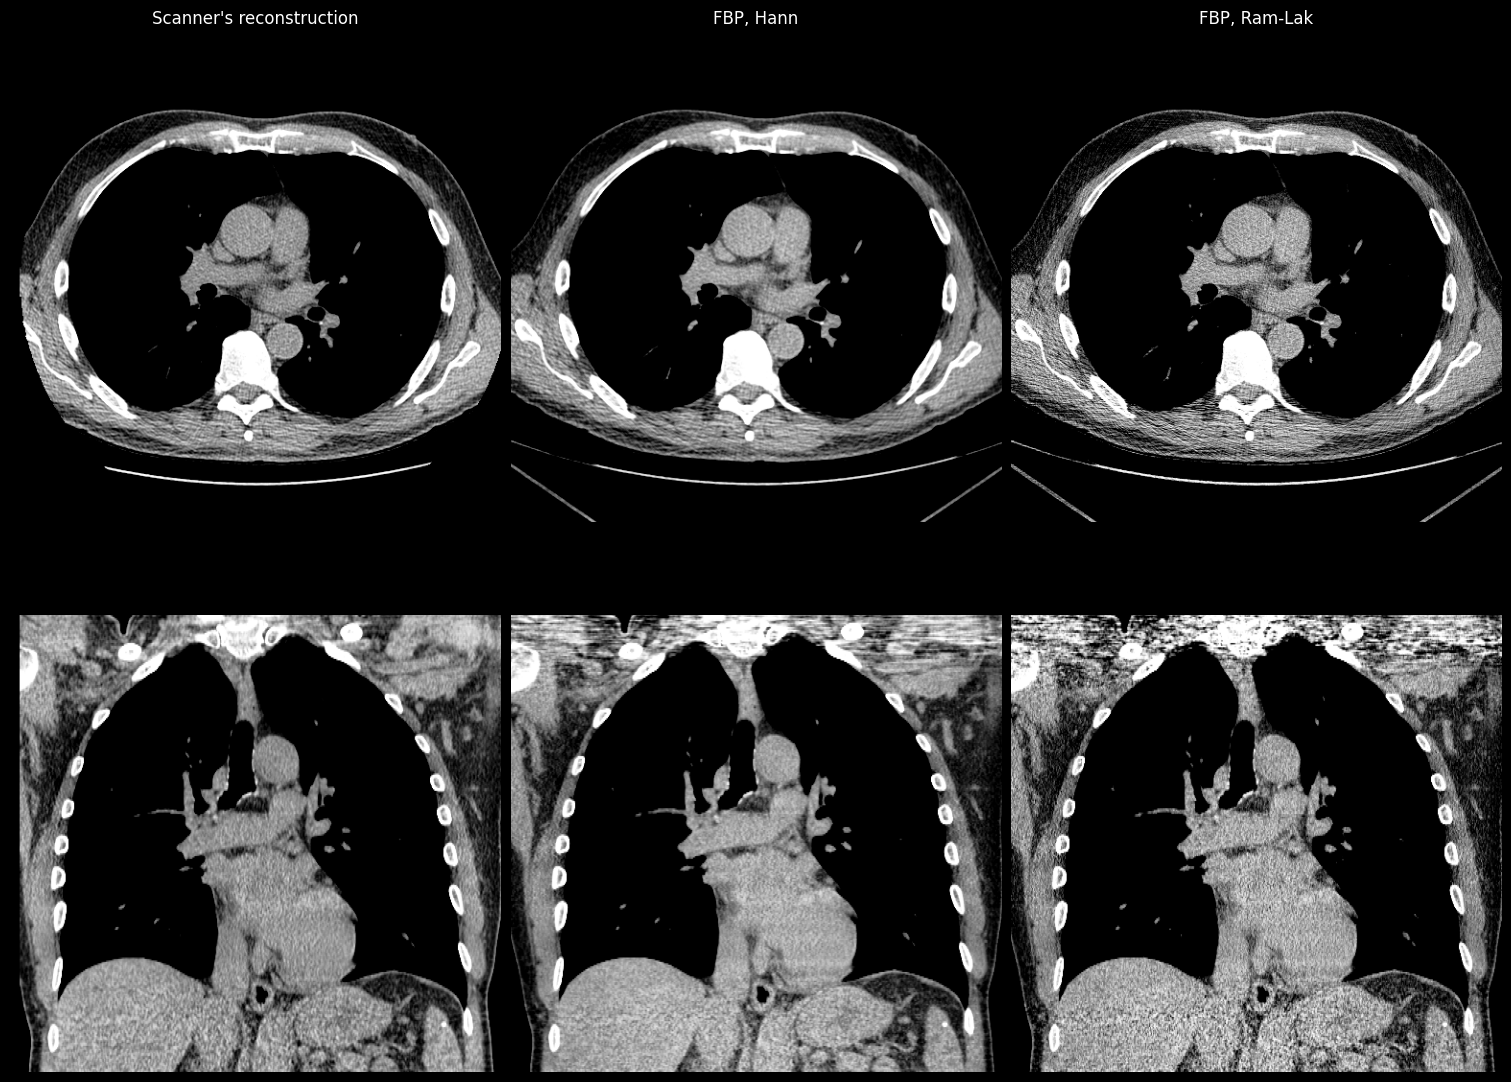

In [11]:
k, j = 157, 256  # an axial slice through the chest, a coronal slice through the middle (k runs from the feet up)
images = [("Scanner's reconstruction", scanner_hu), ('FBP, Hann', hu), ('FBP, Ram-Lak', hu_ramlak)]
aspect = object_meta.dr[2] / object_meta.dr[0]
fig, axes = plt.subplots(2, 3, figsize=(15, 11.3), height_ratios=[1, 316 * aspect / 512], constrained_layout=True)
fig.patch.set_facecolor('black')
for col, (name, image) in enumerate(images):
    axes[0, col].imshow(image[:, :, k].T, cmap='Greys_r', vmin=-160, vmax=240)
    axes[1, col].imshow(image[:, j, :].T, cmap='Greys_r', vmin=-160, vmax=240, aspect=aspect, origin='lower')  # the head at the top
    axes[0, col].set_title(name, color='white')
for ax in axes.flat:
    ax.axis('off')
plt.show()

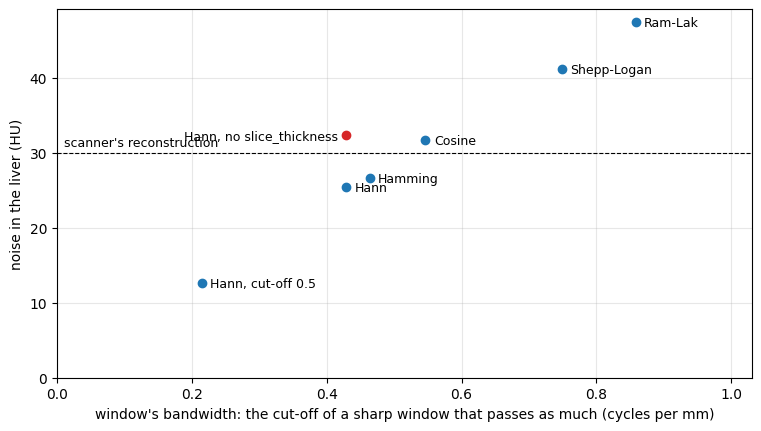

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
for name, sd in noise.items():
    x = bandwidth['Hann' if name == 'Hann, no slice_thickness' else name]
    ax.plot(x, sd, 'o', color='tab:red' if 'slice_thickness' in name else 'tab:blue')
    left = 'slice_thickness' in name  # its label goes left, clear of Cosine's
    ax.annotate(name, (x, sd), textcoords='offset points', xytext=(-6, -3) if left else (6, -3), ha='right' if left else 'left', fontsize=9)
ax.axhline(scanner_hu[liver].std(), color='k', lw=0.8, ls='--')
ax.text(0.01, scanner_hu[liver].std() + 1, "scanner's reconstruction", fontsize=9)
ax.set(xlabel="window's bandwidth: the cut-off of a sharp window that passes as much (cycles per mm)",
       ylabel='noise in the liver (HU)', xlim=(0, f_nyquist * 1.2), ylim=(0, None))
ax.grid(alpha=0.3)
plt.show()

In [13]:
valid = scanner_hu > -1500  # inside the scanner's field of view
blur = lambda a: ndimage.gaussian_filter(np.where(valid, a, -1000.0), 2 / object_meta.dr[0])  # 2 mm
body = valid & (blur(scanner_hu) > -700)
for name, image in images[1:]:
    rms = np.sqrt(((blur(image) - blur(scanner_hu))[body] ** 2).mean())
    print(f"{name:13s} RMS difference from the scanner's image after a 2 mm blur: {rms:4.1f} HU")

FBP, Hann     RMS difference from the scanner's image after a 2 mm blur: 20.0 HU


FBP, Ram-Lak  RMS difference from the scanner's image after a 2 mm blur: 19.9 HU


The noise grows with the window's bandwidth, and faster than in proportion: the ramp amplifies each frequency's noise by the frequency, so the highest frequencies carry the most. Ram-Lak, which keeps every frequency the rays sample, is almost twice as noisy as Hann (47.5 against 25.5 HU in the liver); Hann with its cut-off at half the Nyquist frequency halves the noise again (12.6 HU), at the price of all detail above 0.43 cycles per mm. The scanner's STANDARD kernel, at 30.0 HU, sits between Hann and Cosine. Without `slice_thickness`, Hann's slices average only over the reconstruction's own resolution along the table, and the noise rises by about a quarter (32.4 HU): slice thickness trades resolution along the table for noise, as the window does in the plane.

Against the scanner's image, both windows differ by about 20 HU (RMS) over the body after a 2 mm blur, which removes the difference in noise. Two differences remain that no window removes: streaks at the top of the coronal view, where the scan ends, and a slow trend from the centre of the body outwards (our liver reads about 9 HU higher). The advanced part of the [DICOM-CT-PD tutorial](t_CT_GEN3.ipynb) removes the trend with a calibration fitted to the scanner's images, and fits the scanner's kernel as a window.

## Save the images

`io.save_dicom` writes the Hann image as a DICOM CT series in HU, one file per slice, where `object_meta` places it in the patient. `slice_thickness=1.25` records the thickness each slice averages over (they are 1 mm apart). `reference=scanner_files[0]` gives it the patient, study and frame of reference of the scanner's images, so DICOM viewers show the two together.

In [14]:
saved = io.save_dicom(hu, OUTPUT / 't_fbp_ct' / 'fbp_hann', object_meta, units='HU', slice_thickness=1.25,
                      reference=scanner_files[0], series_description='FBP, Hann, 1.25 mm', overwrite=True)

## Next steps

- The [DICOM-CT-PD tutorial](t_CT_GEN3.ipynb) takes this scan through the whole clinical workflow, and fits the scanner's own kernel as a window to reproduce its images within a few HU.
- The [cone-beam micro-CT tutorial](t_CT_microct.ipynb) uses the same class for FDK, the filtered back projection of cone-beam scans.
- The [SPECT version](t_fbp_spect.ipynb) uses the same class on a SPECT scan, where the counts call for a much lower cut-off.